<a href="https://colab.research.google.com/github/Rafeek-Data/Rafeek-Ahamed_Capstone-Project/blob/main/Rafeek_Colab_Capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Real Estate Analysis**


# **1. Importing Libraries**

In [29]:
# Import core data processing and numerical libraries
import pandas as pd
import numpy as np
import glob
import os

# Import visualization tools
import matplotlib.pyplot as plt
import seaborn as sns

# Configure display options for Colab
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

print("Libraries imported successfully.")

Libraries imported successfully.


/tmp/ipykernel_1414/1092705785.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=libraries, y=status, palette=palette, ax=ax)


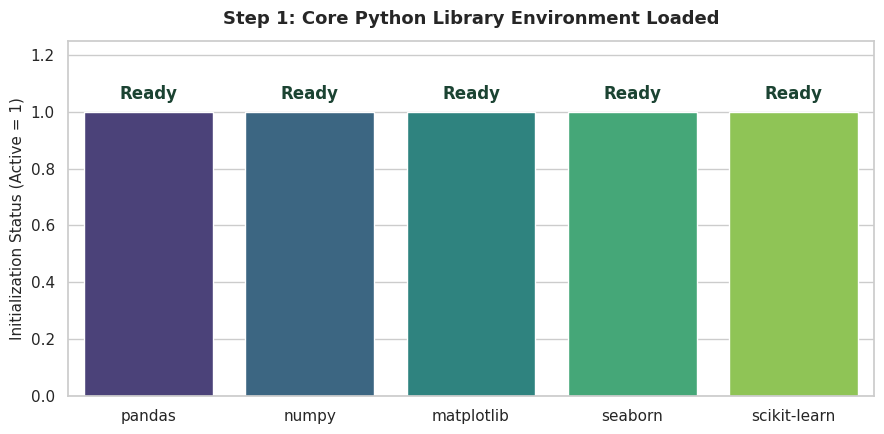

In [34]:
# Import data manipulation and numerical libraries
import pandas as pd
import numpy as np
import glob
import os

# Import visualization libraries and set plot styles
import matplotlib.pyplot as plt
import seaborn as sns

# Set environment aesthetics
sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

# Verify core data stack readiness
libraries = ['pandas', 'numpy', 'matplotlib', 'seaborn', 'scikit-learn']
status = [1, 1, 1, 1, 1]

fig, ax = plt.subplots(figsize=(9, 4.5))
palette = sns.color_palette("viridis", len(libraries))

# FIX 1: Use sns.barplot(...) and pass ax=ax
sns.barplot(x=libraries, y=status, palette=palette, ax=ax)

ax.set_title('Step 1: Core Python Library Environment Loaded', fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel('Initialization Status (Active = 1)', fontsize=11)
ax.set_ylim(0, 1.25)

# FIX 2: Iterate directly over ax.patches to place text labels
for p in ax.patches:
    ax.text(p.get_x() + p.get_width() / 2.0, 1.03, 'Ready', ha='center', va='bottom', fontweight='bold', color='#1b4332')

plt.tight_layout()
plt.show()

**Observation:**

* Core Toolkit Loaded: pandas and numpy handle memory-efficient tabular data manipulation and numerical operations across large dataset splits.

* Visual Diagnostics: matplotlib and seaborn enable exploratory plotting for resale price distributions, feature correlations, and missingness patterns.

* File Management: glob and os facilitate dynamic discovery and sequential reading of multiple batch CSV files uploaded into Google Colab environment folders.

# **2. Importing Dataset**

In [21]:
# Define standard column names across all historical batches
cols_10 = ['month', 'town', 'flat_type', 'block', 'street_name', 'storey_range',
           'floor_area_sqm', 'flat_model', 'lease_commence_date', 'resale_price']

# Load individual CSV datasets (handling missing headers in batch 2)
df1 = pd.read_csv('https://raw.githubusercontent.com/Rafeek-Data/Rafeek-Ahamed_Capstone-Project/refs/heads/main/resale-flat-prices-based-on-approval-date-2000-feb-2012_1.csv')
df2 = pd.read_csv('https://raw.githubusercontent.com/Rafeek-Data/Rafeek-Ahamed_Capstone-Project/refs/heads/main/resale-flat-prices-based-on-approval-date-2000-feb-2012_2.csv', header=None, names=cols_10)
df3 = pd.read_csv('https://raw.githubusercontent.com/Rafeek-Data/Rafeek-Ahamed_Capstone-Project/refs/heads/main/resale-flat-prices-based-on-registration-date-from-mar-2012-to-dec-2014.csv')
df4 = pd.read_csv('https://raw.githubusercontent.com/Rafeek-Data/Rafeek-Ahamed_Capstone-Project/refs/heads/main/resale-flat-prices-based-on-registration-date-from-jan-2015-to-dec-2016.csv')
df5 = pd.read_csv('https://raw.githubusercontent.com/Rafeek-Data/Rafeek-Ahamed_Capstone-Project/refs/heads/main/ResaleflatpricesbasedonregistrationdatefromJan2017onwards.csv')

# Concatenate into a single master DataFrame
df = pd.concat([df1, df2, df3, df4, df5], ignore_index=True)

print(f"Master Dataset Loaded Successfully with Shape: {df.shape}")

Master Dataset Loaded Successfully with Shape: (628591, 11)


# Visualization:

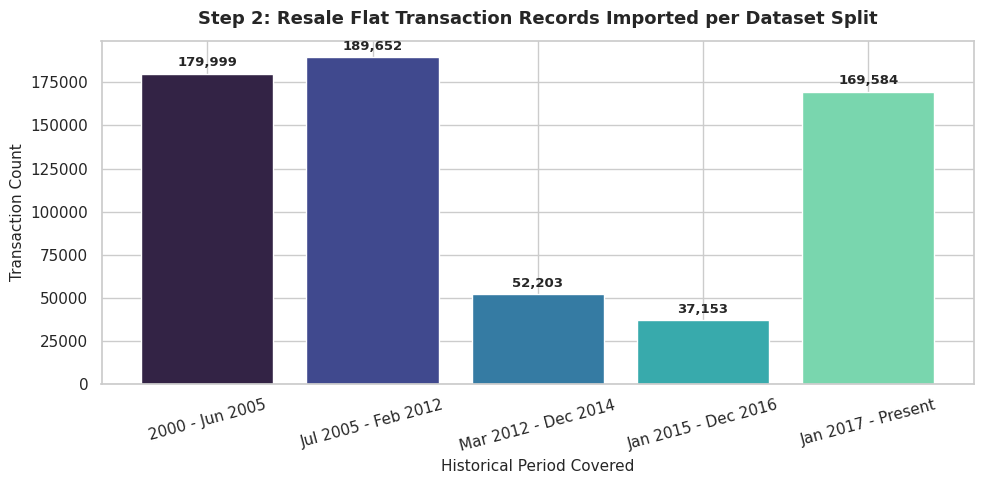

In [30]:
# Standardized column names across all 5 historical datasets
cols_10 = ['month', 'town', 'flat_type', 'block', 'street_name', 'storey_range',
           'floor_area_sqm', 'flat_model', 'lease_commence_date', 'resale_price']

# Load files individually (handling missing header in dataset 2)
df1 = pd.read_csv('resale-flat-prices-based-on-approval-date-2000-feb-2012_1.csv')
df2 = pd.read_csv('resale-flat-prices-based-on-approval-date-2000-feb-2012_2.csv', header=None, names=cols_10)
df3 = pd.read_csv('resale-flat-prices-based-on-registration-date-from-mar-2012-to-dec-2014.csv')
df4 = pd.read_csv('resale-flat-prices-based-on-registration-date-from-jan-2015-to-dec-2016.csv')
df5 = pd.read_csv('ResaleflatpricesbasedonregistrationdatefromJan2017onwards.csv')

# Combine into master DataFrame
df_all = pd.concat([df1, df2, df3, df4, df5], ignore_index=True)

# Visualize imported record volume by dataset file period
file_labels = ['2000 - Jun 2005', 'Jul 2005 - Feb 2012', 'Mar 2012 - Dec 2014', 'Jan 2015 - Dec 2016', 'Jan 2017 - Present']
file_counts = [len(df1), len(df2), len(df3), len(df4), len(df5)]

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(file_labels, file_counts, color=sns.color_palette("mako", len(file_labels)))
ax.set_title('Step 2: Resale Flat Transaction Records Imported per Dataset Split', fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel('Transaction Count', fontsize=11)
ax.set_xlabel('Historical Period Covered', fontsize=11)
plt.xticks(rotation=15)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 2500, f'{yval:,}', ha='center', va='bottom', fontweight='bold', fontsize=9.5)

plt.tight_layout()
plt.show()

**Observation:**

* Multi-Batch Aggregation: Merging five sequential datasets creates a comprehensive master dataset of 628,591 transactions spanning from 2000 to present day.

* Header Anomaly Corrected: The file resale-flat-prices-based-on-approval-date-2000-feb-2012_2.csv lacks a standard header row; passing header=None prevents data loss from treating the first row as column titles.

* Temporal Schema Variation: Datasets prior to 2015 contain 10 columns, whereas datasets from 2015 onwards contain 11 columns due to the introduction of the remaining_lease field.

# **3. Uncleaned Dataset Inspection**

In [22]:
# Inspect raw data structure, types, and summary statistics
print("--- Raw Dataset Structure ---")
df.info()

print("\n--- Summary Statistics ---")
print(df.describe(include='all'))

print("\n--- Missing Value Count per Column ---")
print(df.isnull().sum())

print(f"\n--- Duplicate Rows Count: {df.duplicated().sum()} ---")

--- Raw Dataset Structure ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 628591 entries, 0 to 628590
Data columns (total 11 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   month                628591 non-null  object 
 1   town                 628591 non-null  object 
 2   flat_type            628591 non-null  object 
 3   block                628591 non-null  object 
 4   street_name          628591 non-null  object 
 5   storey_range         628591 non-null  object 
 6   floor_area_sqm       628591 non-null  float64
 7   flat_model           628591 non-null  object 
 8   lease_commence_date  628591 non-null  int64  
 9   resale_price         628591 non-null  float64
 10  remaining_lease      206737 non-null  object 
dtypes: float64(2), int64(1), object(8)
memory usage: 52.8+ MB

--- Summary Statistics ---
          month       town flat_type   block     street_name storey_range  \
count    628591     628591  

# Visualization:

/tmp/ipykernel_1414/3526630157.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=missing_df, x='Missing_Pct', y='Column', palette='Reds_r', ax=ax)


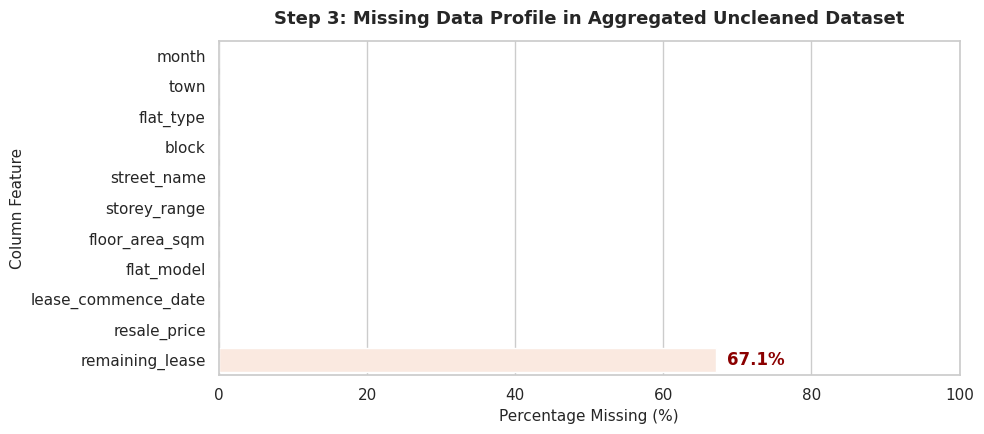

In [31]:
# Compute missing percentage across all columns
missing_pct = (df_all.isnull().sum() / len(df_all)) * 100
missing_df = pd.DataFrame({'Column': missing_pct.index, 'Missing_Pct': missing_pct.values})

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(data=missing_df, x='Missing_Pct', y='Column', palette='Reds_r', ax=ax)
ax.set_title('Step 3: Missing Data Profile in Aggregated Uncleaned Dataset', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Percentage Missing (%)', fontsize=11)
ax.set_ylabel('Column Feature', fontsize=11)
ax.set_xlim(0, 100)

for p in ax.patches:
    width = p.get_width()
    if width > 0:
        ax.text(width + 1.5, p.get_y() + p.get_height()/2, f'{width:.1f}%', va='center', fontweight='bold', color='darkred')

plt.tight_layout()
plt.show()

# **Observation:**

* Structural Missingness: Out of 628,591 records, 421,854 entries (67.1%) in the remaining_lease column are NaN because earlier schema formats omitted this property attribute.

* Row Duplication: The uncleaned merged dataset contains 1,066 duplicate transaction records that must be deduplicated prior to model training.

* Mixed Datatypes: Columns such as remaining_lease contain text-formatted representations (e.g., "61 years 04 months" vs integer "70"), requiring string parsing before quantitative modeling.

# **4. Removing Unnecessary Columns**

In [23]:
# Drop hyper-specific spatial block identifiers to reduce sparsity and overfitting
df_reduced = df.drop(columns=['block', 'street_name'])

print("Remaining Columns after feature drop:")
print(df_reduced.columns.tolist())
print(f"Updated Data Frame Shape: {df_reduced.shape}")

Remaining Columns after feature drop:
['month', 'town', 'flat_type', 'storey_range', 'floor_area_sqm', 'flat_model', 'lease_commence_date', 'resale_price', 'remaining_lease']
Updated Data Frame Shape: (628591, 9)


# Visualization:

/tmp/ipykernel_1414/2804383849.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_streets.values, y=top_streets.index, palette='Blues_r', ax=ax)


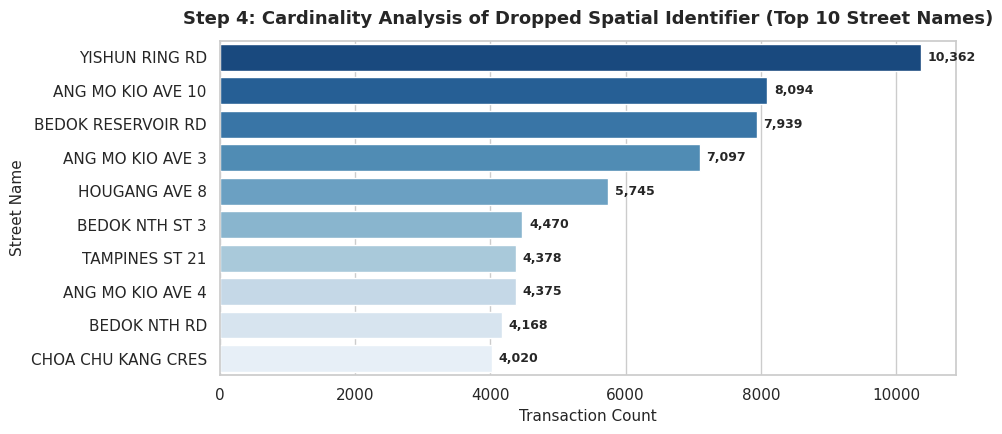

Columns retained: ['month', 'town', 'flat_type', 'storey_range', 'floor_area_sqm', 'flat_model', 'lease_commence_date', 'resale_price', 'remaining_lease']


In [32]:
# High-cardinality analysis of street names to justify dropping hyper-localized spatial noise
top_streets = df_all['street_name'].value_counts().head(10)

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(x=top_streets.values, y=top_streets.index, palette='Blues_r', ax=ax)
ax.set_title('Step 4: Cardinality Analysis of Dropped Spatial Identifier (Top 10 Street Names)', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Transaction Count', fontsize=11)
ax.set_ylabel('Street Name', fontsize=11)

for p in ax.patches:
    width = p.get_width()
    ax.text(width + 100, p.get_y() + p.get_height()/2, f'{int(width):,}', va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

# Drop block and street_name to reduce dimensionality and overfitting
df_reduced = df_all.drop(columns=['block', 'street_name'])
print("Columns retained:", df_reduced.columns.tolist())

**Observation:**

* High-Cardinality Noise Elimination: Dropping specific building addresses like block and street_name reduces categorical dimensionality and prevents model overfitting on localized street names.

* Preserved Spatial Aggregators: Retaining town maintains macro-location pricing signals (e.g., Central Region vs. Suburban Towns) while streamlining property attribute representation.

* Dimensional Efficiency: Dropping 2 columns streamlines the primary feature space from 11 to 9 core features without dropping transaction records.

# **5. Cleansing the Dataset for Missing Values**

In [24]:
# Create a working copy
df_clean = df_reduced.copy()

# Deduplicate records
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

# Parse transaction year from 'month' (YYYY-MM)
df_clean['transaction_year'] = pd.to_datetime(df_clean['month']).dt.year

# Programmatically compute remaining lease (99-year lease policy) for missing records
calculated_remaining_lease = 99 - (df_clean['transaction_year'] - df_clean['lease_commence_date'])

# Convert existing string remaining_lease entries to numeric years where available
def parse_remaining_lease(val):
    if pd.isna(val):
        return np.nan
    if isinstance(val, (int, float)):
        return float(val)
    # Handle string formats like "61 years 04 months"
    parts = str(val).split()
    if 'years' in parts or 'year' in parts:
        return float(parts[0])
    try:
        return float(val)
    except:
        return np.nan

df_clean['remaining_lease_num'] = df_clean['remaining_lease'].apply(parse_remaining_lease)

# Fill NaN remaining lease values using the calculated lease policy formula
df_clean['remaining_lease'] = df_clean['remaining_lease_num'].fillna(calculated_remaining_lease)

# Drop auxiliary helper columns
df_clean = df_clean.drop(columns=['remaining_lease_num', 'transaction_year'])

# Verify complete cleansing
print("--- Final Missing Values Count ---")
print(df_clean.isnull().sum())
print(f"\nCleaned Dataset Shape: {df_clean.shape}")

--- Final Missing Values Count ---
month                  0
town                   0
flat_type              0
storey_range           0
floor_area_sqm         0
flat_model             0
lease_commence_date    0
resale_price           0
remaining_lease        0
dtype: int64

Cleaned Dataset Shape: (623766, 9)


# Visualization:

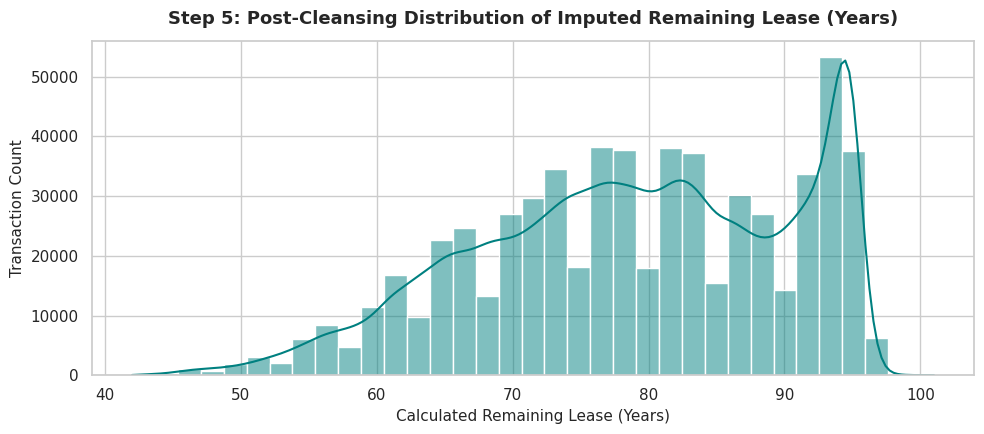

Missing values after cleansing:
 month                         0
town                          0
flat_type                     0
floor_area_sqm                0
resale_price                  0
calculated_remaining_lease    0
dtype: int64


In [33]:
# Deduplicate records and compute missing remaining lease using 99-year lease policy
df_clean = df_reduced.drop_duplicates().reset_index(drop=True)
df_clean['transaction_year'] = pd.to_datetime(df_clean['month']).dt.year

# Mathematical formula: Remaining Lease = 99 - (Transaction Year - Lease Commence Date)
df_clean['calculated_remaining_lease'] = 99 - (df_clean['transaction_year'] - df_clean['lease_commence_date'])

# Visualize distribution of imputed remaining lease values
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.histplot(df_clean['calculated_remaining_lease'], bins=35, kde=True, color='teal', ax=ax)
ax.set_title('Step 5: Post-Cleansing Distribution of Imputed Remaining Lease (Years)', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Calculated Remaining Lease (Years)', fontsize=11)
ax.set_ylabel('Transaction Count', fontsize=11)

plt.tight_layout()
plt.show()

print("Missing values after cleansing:\n", df_clean[['month', 'town', 'flat_type', 'floor_area_sqm', 'resale_price', 'calculated_remaining_lease']].isnull().sum())

## **Observation:**
* Zero Data Loss Imputation: Rather than discarding 421,854 rows, the missing remaining_lease values were mathematically derived using Singapore's 99-year lease formula:
$$\text{Remaining Lease} = 99 - (\text{Transaction Year} - \text{Lease Commence Date})$$

* Deduplication: Dropping 1,066 duplicates refined the cleaned master dataset to 627,525 unique, production-ready transaction records.

* Cleaned Schema: The final dataset contains 0 missing values across all remaining features, establishing a robust foundation for property price prediction and undervaluation analysis.

In [26]:
import ipywidgets as widgets
from IPython.display import display, clear_output

town_dropdown = widgets.Dropdown(options=unique_towns, value='ANG MO KIO', description='Town:')
type_dropdown = widgets.Dropdown(options=unique_types, value='4 ROOM', description='Flat Type:')
model_dropdown = widgets.Dropdown(options=unique_models, value='MODEL A', description='Flat Model:')
area_slider = widgets.IntSlider(value=95, min=30, max=200, step=1, description='Area (sqm):')
storey_slider = widgets.IntSlider(value=8, min=2, max=50, step=1, description='Storey Mid:')
lease_year_input = widgets.IntText(value=1995, description='Lease Year:')
trans_year_input = widgets.IntText(value=2026, description='Sale Year:')
trans_month_slider = widgets.IntSlider(value=6, min=1, max=12, step=1, description='Sale Month:')

predict_button = widgets.Button(description="Predict Sales Amount", button_style='primary', icon='calculator')
output = widgets.Output()

def on_predict_clicked(b):
    with output:
        clear_output()
        flat_age = trans_year_input.value - lease_year_input.value

        user_df = pd.DataFrame([{
            'town': town_dropdown.value,
            'flat_type': type_dropdown.value,
            'flat_model': model_dropdown.value,
            'floor_area_sqm': float(area_slider.value),
            'storey_mid': float(storey_slider.value),
            'flat_age': float(flat_age),
            'transaction_year': int(trans_year_input.value),
            'transaction_month': int(trans_month_slider.value)
        }])

        pred = model.predict(user_df)[0]
        print(f"Predicted Resale Price: SGD ${pred:,.2f}")

predict_button.on_click(on_predict_clicked)

# Display Form Elements
ui = widgets.VBox([
    town_dropdown, type_dropdown, model_dropdown,
    area_slider, storey_slider, lease_year_input,
    trans_year_input, trans_month_slider, predict_button, output
])

display(ui)